In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import  accuracy_score,classification_report,confusion_matrix
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
import warnings

warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv(r'c:\Users\DELL\Downloads\Social_media_impact_on_life.csv')

In [3]:
df.head()

,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


In [4]:
df.columns

Index(['Student_ID', 'Age', 'Gender', 'Academic_Level', 'Primary_Platform',
       'Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Device_Type',
       'Sleep_Duration_Hours', 'Sleep_Quality_Score', 'Late_Night_Usage',
       'Social_Comparison_Frequency', 'Perceived_Stress_Score',
       'Mental_Health_Index', 'Academic_Performance_GPA', 'Overall_Impact'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Student_ID                   4500 non-null   str    
 1   Age                          4500 non-null   int64  
 2   Gender                       4500 non-null   str    
 3   Academic_Level               4500 non-null   str    
 4   Primary_Platform             4500 non-null   str    
 5   Daily_Usage_Hours            4500 non-null   float64
 6   Weekend_Extra_Hours          4500 non-null   float64
 7   Device_Type                  4500 non-null   str    
 8   Sleep_Duration_Hours         4500 non-null   float64
 9   Sleep_Quality_Score          4500 non-null   int64  
 10  Late_Night_Usage             4500 non-null   bool   
 11  Social_Comparison_Frequency  4500 non-null   str    
 12  Perceived_Stress_Score       4454 non-null   float64
 13  Mental_Health_Index          

In [6]:
df.shape

(4500, 16)

In [7]:
df['Late_Night_Usage'].unique()

array([ True, False])

In [8]:
df['Gender'] = df['Gender'].map({'Female':0, 'Male':1, 'Non-Binary':2, 'Prefer not to say':3})


In [9]:
df.head()

,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,0,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,0,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,0,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,0,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,1,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Student_ID                   4500 non-null   str    
 1   Age                          4500 non-null   int64  
 2   Gender                       4500 non-null   int64  
 3   Academic_Level               4500 non-null   str    
 4   Primary_Platform             4500 non-null   str    
 5   Daily_Usage_Hours            4500 non-null   float64
 6   Weekend_Extra_Hours          4500 non-null   float64
 7   Device_Type                  4500 non-null   str    
 8   Sleep_Duration_Hours         4500 non-null   float64
 9   Sleep_Quality_Score          4500 non-null   int64  
 10  Late_Night_Usage             4500 non-null   bool   
 11  Social_Comparison_Frequency  4500 non-null   str    
 12  Perceived_Stress_Score       4454 non-null   float64
 13  Mental_Health_Index          

In [11]:
df['Perceived_Stress_Score']=df['Perceived_Stress_Score'].fillna(df['Perceived_Stress_Score'].mean())

In [12]:
df = df.dropna(subset=['Academic_Performance_GPA'])

In [13]:
df.isnull().sum()

Student_ID                     0
Age                            0
Gender                         0
Academic_Level                 0
Primary_Platform               0
Daily_Usage_Hours              0
Weekend_Extra_Hours            0
Device_Type                    0
Sleep_Duration_Hours           0
Sleep_Quality_Score            0
Late_Night_Usage               0
Social_Comparison_Frequency    0
Perceived_Stress_Score         0
Mental_Health_Index            0
Academic_Performance_GPA       0
Overall_Impact                 0
dtype: int64

In [14]:
df.drop_duplicates(inplace=True)

<Axes: >

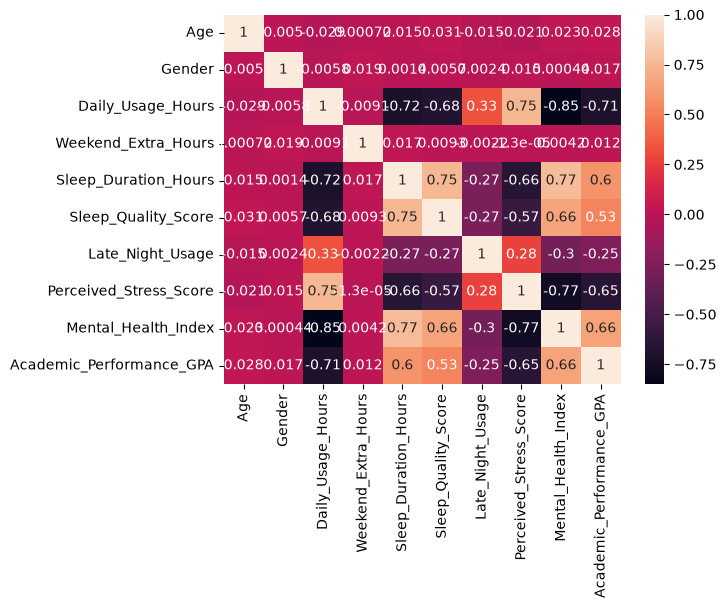

In [15]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

<Axes: xlabel='Late_Night_Usage', ylabel='count'>

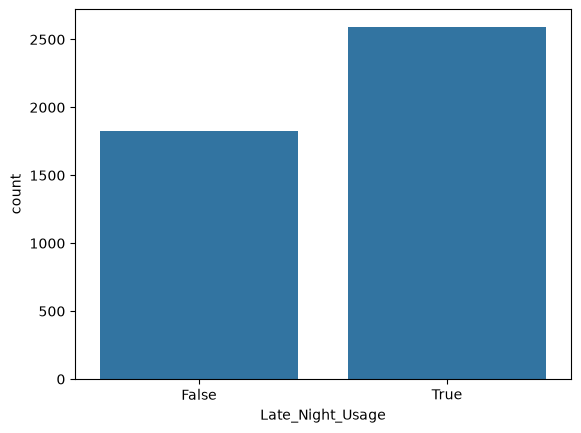

In [16]:
sns.countplot(x=df['Late_Night_Usage'])

In [17]:
df['Late_Night_Usage'] =df['Late_Night_Usage'].map({True:0,False:1})

In [18]:
df.head()

,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,0,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,0,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,0,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,0,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,0,High School,TikTok,10.9,1.7,Smartphone,5.2,1,0,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,0,High School,YouTube,6.0,2.3,Tablet,7.6,4,0,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,1,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,0,Never,16.0,84,3.41,Beneficial


<Axes: xlabel='Device_Type', ylabel='count'>

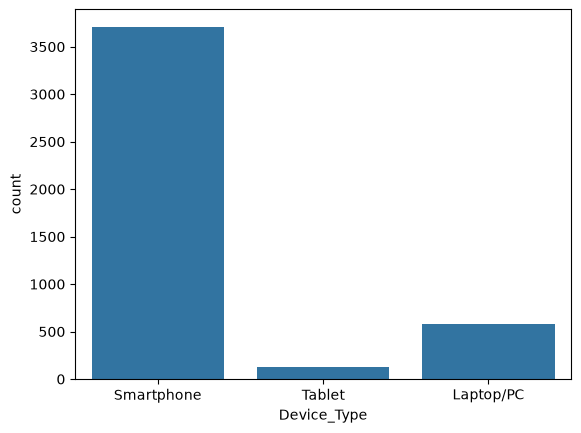

In [19]:
sns.countplot(x=df['Device_Type'])

In [20]:
df.head()

,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,0,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,0,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,0,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,0,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,0,High School,TikTok,10.9,1.7,Smartphone,5.2,1,0,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,0,High School,YouTube,6.0,2.3,Tablet,7.6,4,0,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,1,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,0,Never,16.0,84,3.41,Beneficial


<Axes: xlabel='Academic_Level', ylabel='count'>

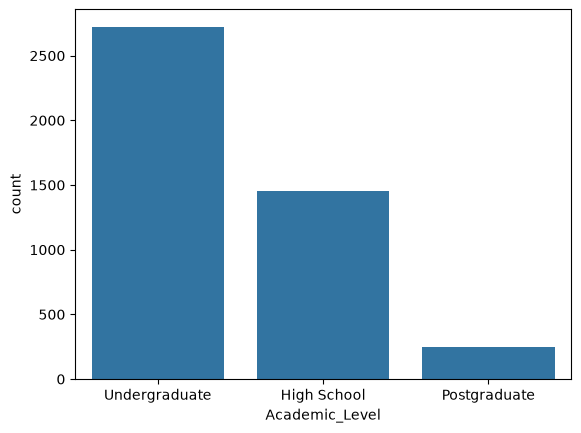

In [21]:
sns.countplot(x=df['Academic_Level'])

<Axes: xlabel='Primary_Platform', ylabel='count'>

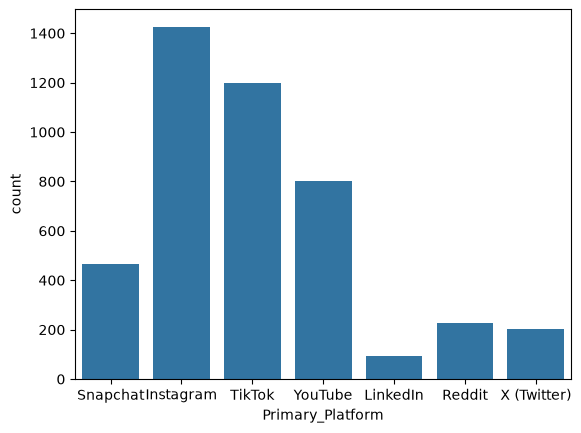

In [22]:
sns.countplot(x=df['Primary_Platform'])

In [23]:
df["Primary_Platform"].unique()

<StringArray>
[   'Snapchat',   'Instagram',      'TikTok',     'YouTube',    'LinkedIn',
      'Reddit', 'X (Twitter)']
Length: 7, dtype: str

<Axes: xlabel='Social_Comparison_Frequency', ylabel='count'>

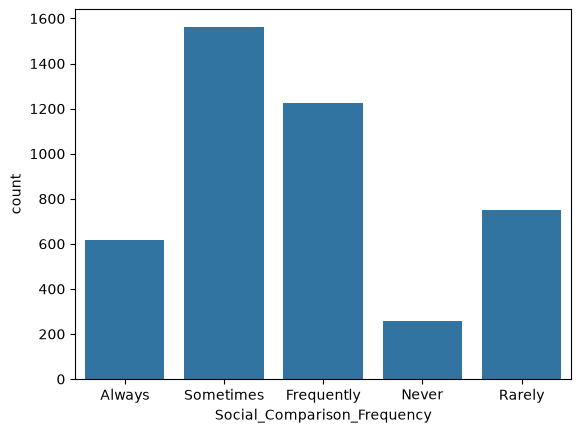

In [24]:
sns.countplot(x=df["Social_Comparison_Frequency"])

<Axes: xlabel='Overall_Impact', ylabel='count'>

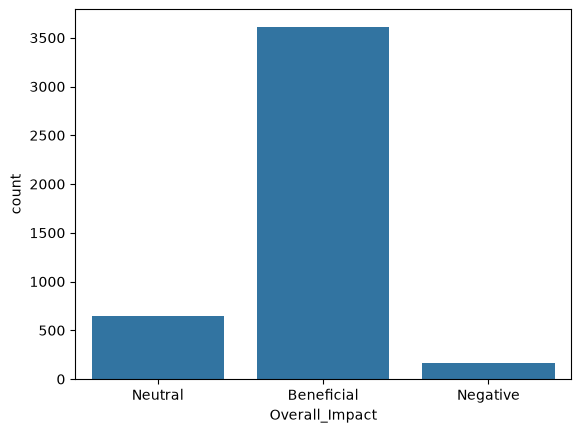

In [25]:
sns.countplot(x=df['Overall_Impact'])

In [26]:
df['Overall_Impact'] = df['Overall_Impact'].map({'Neutral':0,'Beneficial':1,'Negative':2})

In [27]:
df.info()

<class 'pandas.DataFrame'>
Index: 4415 entries, 0 to 4499
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Student_ID                   4415 non-null   str    
 1   Age                          4415 non-null   int64  
 2   Gender                       4415 non-null   int64  
 3   Academic_Level               4415 non-null   str    
 4   Primary_Platform             4415 non-null   str    
 5   Daily_Usage_Hours            4415 non-null   float64
 6   Weekend_Extra_Hours          4415 non-null   float64
 7   Device_Type                  4415 non-null   str    
 8   Sleep_Duration_Hours         4415 non-null   float64
 9   Sleep_Quality_Score          4415 non-null   int64  
 10  Late_Night_Usage             4415 non-null   int64  
 11  Social_Comparison_Frequency  4415 non-null   str    
 12  Perceived_Stress_Score       4415 non-null   float64
 13  Mental_Health_Index          4415 

In [28]:
df.columns

Index(['Student_ID', 'Age', 'Gender', 'Academic_Level', 'Primary_Platform',
       'Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Device_Type',
       'Sleep_Duration_Hours', 'Sleep_Quality_Score', 'Late_Night_Usage',
       'Social_Comparison_Frequency', 'Perceived_Stress_Score',
       'Mental_Health_Index', 'Academic_Performance_GPA', 'Overall_Impact'],
      dtype='str')

In [29]:
df_1=df.drop(['Device_Type',
       'Sleep_Duration_Hours', 'Sleep_Quality_Score', 'Late_Night_Usage',
       'Social_Comparison_Frequency', 'Perceived_Stress_Score',
       'Mental_Health_Index', ],axis=1)

<Axes: >

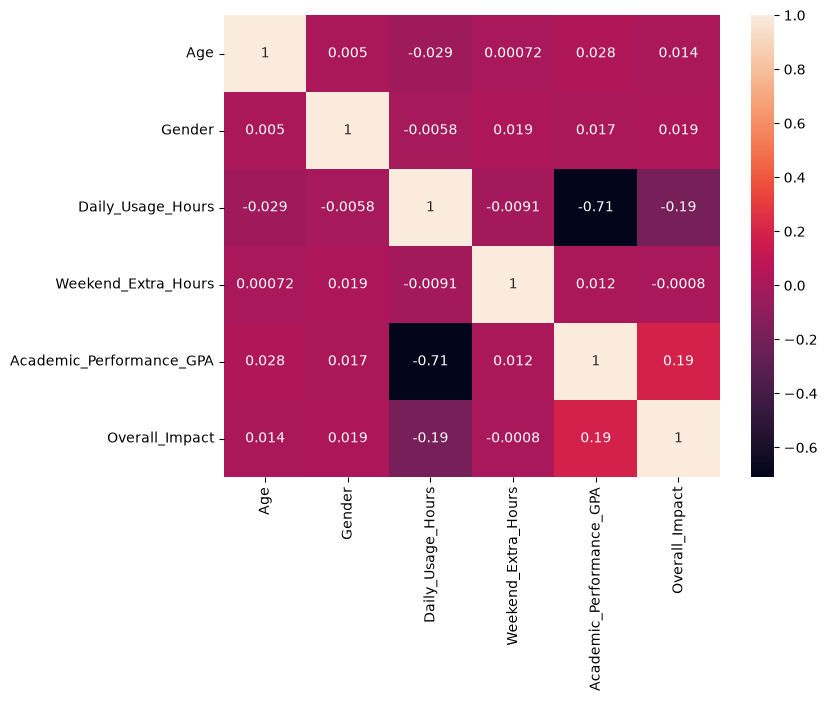

In [30]:
plt.figure(figsize=(8,6))
sns.heatmap(df_1.corr(numeric_only=True),annot=True)

In [31]:
df_2= df.drop(['Student_ID','Age', 'Gender', 'Academic_Level', 'Primary_Platform',
       'Daily_Usage_Hours', 'Weekend_Extra_Hours'],axis=1)

<Axes: >

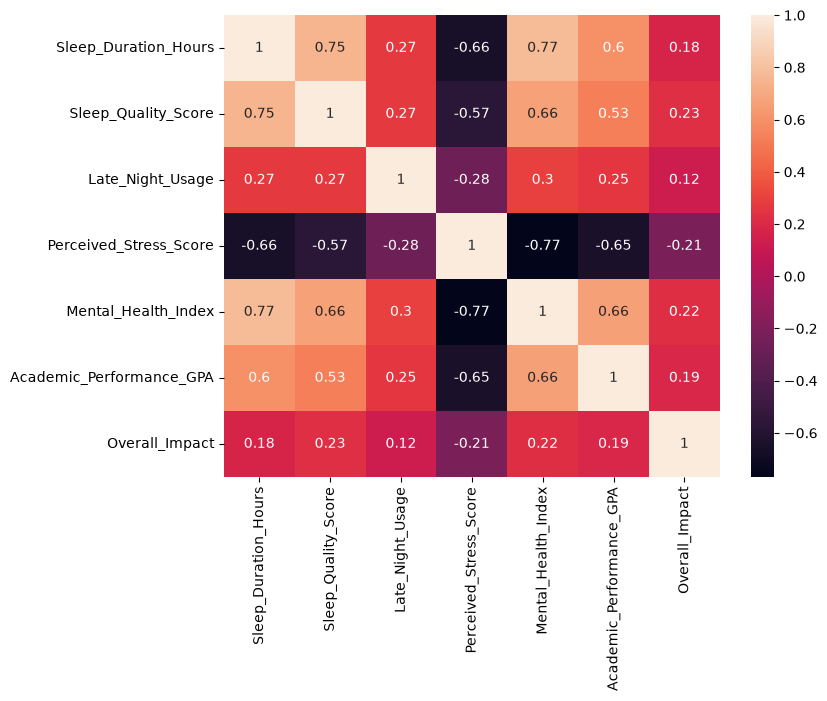

In [32]:
plt.figure(figsize=(8,6))
sns.heatmap(df_2.corr(numeric_only=True),annot=True)

In [33]:
df=df.drop(['Student_ID','Age','Academic_Level','Device_Type', 'Weekend_Extra_Hours'],axis=1)

In [34]:
df.head()

,Gender,Primary_Platform,Daily_Usage_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,0,Snapchat,7.5,5.9,2,0,Always,20.0,73,2.73,0
1,0,Instagram,4.6,7.9,3,0,Sometimes,17.0,90,3.21,1
2,0,TikTok,10.9,5.2,1,0,Frequently,18.0,70,3.00,0
3,0,YouTube,6.0,7.6,4,0,Sometimes,15.0,82,3.42,1
4,1,LinkedIn,3.3,7.6,4,0,Never,16.0,84,3.41,1


In [35]:
df.shape

(4415, 11)

In [36]:
X=df.drop(['Overall_Impact'],axis=1)
y=df['Overall_Impact']

In [37]:
x_encoded = pd.get_dummies(X,['Social_Comparison_Frequency','Primary_Platform'],drop_first=True)

In [38]:
x_encoded=x_encoded.astype(int)

In [39]:
x_encoded.head()

,Gender,Daily_Usage_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Social_Comparison_Frequency_LinkedIn,Social_Comparison_Frequency_Reddit,Social_Comparison_Frequency_Snapchat,Social_Comparison_Frequency_TikTok,Social_Comparison_Frequency_X (Twitter),Social_Comparison_Frequency_YouTube,Primary_Platform_Frequently,Primary_Platform_Never,Primary_Platform_Rarely,Primary_Platform_Sometimes
0,0,7,5,2,0,20,73,2,0,0,1,0,0,0,0,0,0,0
1,0,4,7,3,0,17,90,3,0,0,0,0,0,0,0,0,0,1
2,0,10,5,1,0,18,70,3,0,0,0,1,0,0,1,0,0,0
3,0,6,7,4,0,15,82,3,0,0,0,0,0,1,0,0,0,1
4,1,3,7,4,0,16,84,3,1,0,0,0,0,0,0,1,0,0


In [40]:
X_train, X_test, y_train, y_test = train_test_split( x_encoded, y, test_size=0.20, random_state=42)



In [41]:
lr_model = LogisticRegression()

lr_model.fit(X_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [42]:
y_predict= lr_model.predict(X_test)

In [43]:
print('ACCURACY SCORE OF MY LR_MODEL IS:',accuracy_score(y_predict,y_test)*100)


ACCURACY SCORE OF MY LR_MODEL IS: 96.94224235560588


In [44]:
print(classification_report(y_predict,y_test))

              precision    recall  f1-score   support

           0       0.89      0.89      0.89       121
           1       0.98      0.98      0.98       723
           2       0.95      0.95      0.95        39

    accuracy                           0.97       883
   macro avg       0.94      0.94      0.94       883
weighted avg       0.97      0.97      0.97       883



In [45]:
svc_model = SVC()
svc_model.fit(X_train,y_train)


,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [46]:
y_pred_svc=svc_model.predict(X_test)

In [47]:
print('ACCURACY SCORE OF MY SVC_MODEL IS:',accuracy_score(y_pred_svc,y_test)*100)

ACCURACY SCORE OF MY SVC_MODEL IS: 96.03624009060022


In [48]:
dt_model = DecisionTreeClassifier()

dt_model.fit(X_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [49]:
y_pred_dt = dt_model.predict(X_test)

In [50]:
print('ACCURACY SCORE OF MY DT_MODEL IS:',accuracy_score(y_pred_dt,y_test)*100)

ACCURACY SCORE OF MY DT_MODEL IS: 96.03624009060022


In [51]:
nb_model = MultinomialNB()

nb_model.fit(X_train,y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](3,)","[ 520.,2888., 124.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](3,)","[-1.92,-0.2 ,-3.35]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[0,1,2]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](3, 18)","[[ 293., 4181., 2617.,..., 28., 87., 188.], [ 1656.,11434.,19008.,..., 188., 484., 1009.], [ 88., 1478., 481.,..., 6., 31., 40.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](3, 18)","[[-5.22,-2.57,-3.03,...,-7.54,-6.43,-5.66], [-5.3 ,-3.36,-2.86,...,-7.47,-6.52,-5.79], [-4.93,-2.12,-3.24,...,-7.47,-5.95,-5.71]]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](18,)","['Gender','Daily_Usage_Hours','Sleep_Duration_Hours',..., 'Primary_Platform_Never','Primary_Platform_Rarely', 'Primary_Platform_Sometimes']"


In [52]:
y_pred_nb = nb_model.predict(X_test)

In [53]:
print("ACCURACY SCORE OF MY NB_MODEL IS:",accuracy_score(y_pred_nb,y_test)*100)

ACCURACY SCORE OF MY NB_MODEL IS: 93.99773499433749
